# Solving Inverse Problem using sLORETA

## 📦 Imports

In [12]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

## 🧠 Data

In [13]:
# configuration
sub    = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")
sample = "sample7"

# data
data = mm.io.read_dataset(sub, "gt", "eeg_inv", "fwd", "cst", sample=sample)

noise_cov = mne.make_ad_hoc_cov(data["eeg_inv"].info, std={"eeg":1})

# features
sfreq = data["eeg_inv"].info["sfreq"]


_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

#### 🌟 Visualize ground truth

In [14]:
try:
    print(f"50% rising phase time: {t_half:03}")
    print(f"Peak time: {t_peak:03}")

    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)
except KeyError as e:
    print("No ground truth available.")

50% rising phase time: 0.492
Peak time: 0.536


Widget(value='<iframe src="http://localhost:42395/index.html?ui=P_0x7fd301334110_4&reconnect=auto" class="pyvi…

In [15]:
mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,pt])

#### 🌟 Visualize EEG time series

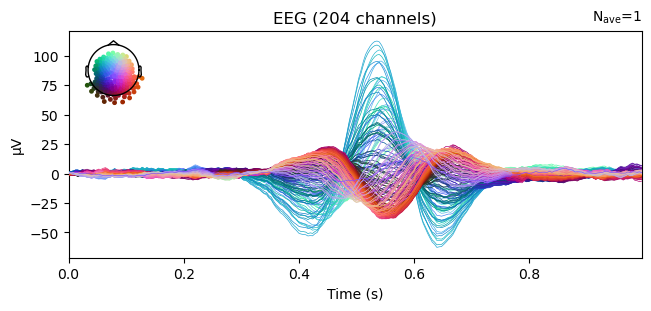

In [16]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

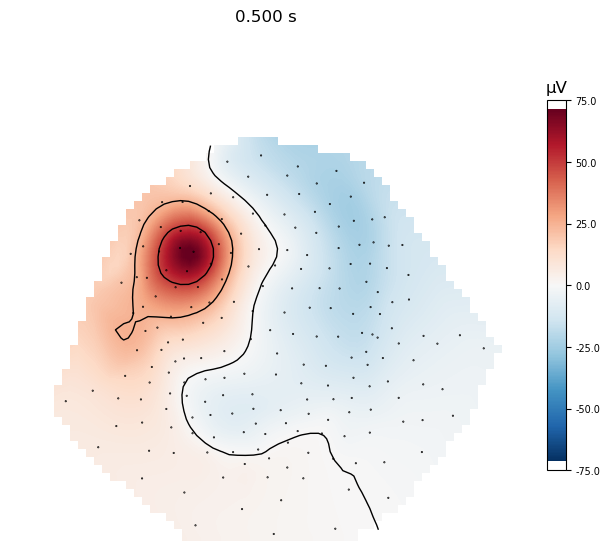

In [17]:
times = [0.5]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

#### 🌟 Visualize forward matrix

In [18]:
mm.viz.plot_leadfield(data["eeg_inv"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:42395/index.html?ui=P_0x7fd31ec3e420_6&reconnect=auto" class="pyvi…

## Solve the inverse problem with sLORETA

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct.
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 24


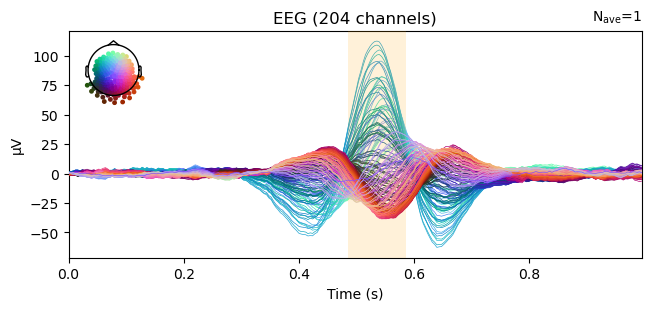

In [19]:
win_size = 0.1      # window size in [s]

_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)
dt   = int(win_size * sfreq /2)
b    = data["eeg_inv"].data[:, pt-dt:pt+dt]

tstart = pt/sfreq-(win_size/2)
tend   = pt/sfreq+(win_size/2)

print(f"Number of samples: {dt*2}")
_ = data["eeg_inv"].plot(highlight=[tstart, tend])

🛠️ <font color=violet>**Select sLORETA parameters**</font>: Select the regularizer parameter $\lambda$

In [20]:
lam = 0.001

⚙️ <font color=green>**Solve inverse problem**</font>

In [21]:
data["eeg_inv"].set_eeg_reference(projection=True)

inverse = mne.minimum_norm.make_inverse_operator(
    data["eeg_inv"].info,
    data["fwd"],
    noise_cov,
    fixed=True,
    depth=None,
    verbose="warning",
)

stc = mne.minimum_norm.apply_inverse(
    data["eeg_inv"], 
    inverse, 
    lambda2=lam,
    method="sLORETA",
    verbose="warning",
)

stc = stc.crop(tstart, tend)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


#### 🌟 Visualize reconstruction

In [22]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], np.abs(stc.data), t_start=tstart, sfreq=data["eeg_inv"].info["sfreq"], cmap="reds")

Widget(value='<iframe src="http://localhost:42395/index.html?ui=P_0x7fd31ebab200_7&reconnect=auto" class="pyvi…

In [25]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(stc.data[:,1]), cmap="reds", show_max=True).show()

Widget(value='<iframe src="http://localhost:42395/index.html?ui=P_0x7fd303fbfaa0_11&reconnect=auto" class="pyv…

#### 💾 Save the sLORETA reconstruction

In [21]:
fname  = f"{sub}_{sample}_sloreta-{lam}"
folder = Path(config["MM_DIR"])/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving sLORETA reconstruction of {sample} from {sub}.")
stc.save(folder/fname, overwrite=True)

Saving sLORETA reconstruction of sample1 from sub-CHUVA002_ses-V1.
Writing STC to disk...
[done]


#### 💾 Save the sLORETA reconstruction in brain vision format

In [ ]:
save = "mne"
#save = "bv"

fname  = f"{sub}_sloreta-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation for subject: {sub}")
if save == "mne":
    stc.save(folder/fname, overwrite=True)
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )